In [2]:
!pip install pyspark

In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AnalisisAccidentalidadVial") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

print("Spark iniciado correctamente")

Spark iniciado correctamente


In [4]:
import os

print(os.listdir('/content'))

['.config', 'VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261027.csv', 'sample_data']


In [5]:
ruta = "/content/VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261027.csv"

df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .option("encoding", "UTF-8") \
    .csv(ruta)

print("Archivo cargado correctamente")

Archivo cargado correctamente


In [6]:
print("Cantidad de registros:", df.count())

print("\nColumnas del dataset:")
print(df.columns)

print("\nPrimeros 10 registros:")
df.show(10, truncate=False)

Cantidad de registros: 450335

Columnas del dataset:
['MARCA_VEHICULO', 'MODELO_VEHICULO', 'TIPO_VEHICULO', 'EDAD_VEHICULO', 'FECHA_ACCIDENTE', 'GRAVEDAD_ACCIDENTE', 'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE', 'AUTORIDAD_DE_TRANSITO']

Primeros 10 registros:
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO             |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|VOLKSWAGEN    |2018           |CAMION       |7            |09/2026        |CON HERIDOS       |ANTIOQUIA             |MEDELLIN           |DIRECCION DE TRANSITO Y TRANSPORTE|
|AKT           |2024           |MOTOCICL

In [7]:
from pyspark.sql import functions as F

# Columnas de texto que vamos a limpiar
columnas_texto = [
    "MARCA_VEHICULO",
    "TIPO_VEHICULO",
    "FECHA_ACCIDENTE",
    "GRAVEDAD_ACCIDENTE",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE",
    "AUTORIDAD_DE_TRANSITO"
]

# Eliminar espacios al inicio y al final
for columna in columnas_texto:
    df = df.withColumn(
        columna,
        F.trim(F.col(columna))
    )

# Convertir cadenas vacías en valores nulos
for columna in columnas_texto:
    df = df.withColumn(
        columna,
        F.when(F.col(columna) == "", None)
         .otherwise(F.col(columna))
    )

print("Limpieza inicial completada")
print("Registros después de la limpieza:", df.count())

df.show(5, truncate=False)

Limpieza inicial completada
Registros después de la limpieza: 450335
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO             |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|VOLKSWAGEN    |2018           |CAMION       |7            |09/2026        |CON HERIDOS       |ANTIOQUIA             |MEDELLIN           |DIRECCION DE TRANSITO Y TRANSPORTE|
|AKT           |2024           |MOTOCICLETA  |3            |09/2026        |CON HERIDOS       |ANTIOQUIA             |MEDELLIN           |DIRECCION DE TRANSITO Y TRANSPORTE|
|YAMAHA        |2022           |MOTOCICLETA  |5            |0

In [8]:
# Contar valores nulos por columna
df.select([
    F.count(
        F.when(F.col(c).isNull(), c)
    ).alias(c)
    for c in df.columns
]).show(truncate=False)

+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO|
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|0             |0              |0            |20           |0              |0                 |0                     |0                  |0                    |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+



In [9]:
total_registros = df.count()
registros_unicos = df.dropDuplicates().count()

print("Total de registros:", total_registros)
print("Registros únicos:", registros_unicos)
print("Posibles duplicados:", total_registros - registros_unicos)

Total de registros: 450335
Registros únicos: 290936
Posibles duplicados: 159399


In [10]:
vehiculos = df.groupBy("TIPO_VEHICULO") \
    .count() \
    .orderBy(F.desc("count"))

vehiculos.show(20, truncate=False)

+---------------+------+
|TIPO_VEHICULO  |count |
+---------------+------+
|MOTOCICLETA    |255266|
|AUTOMOVIL      |99900 |
|CAMIONETA      |38438 |
|BUS            |17439 |
|CAMION         |12274 |
|CAMPERO        |9691  |
|TRACTOCAMION   |5797  |
|MICROBUS       |4813  |
|BUSETA         |3168  |
|VOLQUETA       |2221  |
|MOTOCARRO      |1048  |
|CICLOMOTOR     |160   |
|CUATRIMOTO     |32    |
|CUADRICICLO    |21    |
|TRACTOR        |16    |
|MAQ. AGRICOLA  |10    |
|MONTACARGAS    |9     |
|RETROEXCAVADORA|5     |
|MINICARGADOR   |4     |
|CARGADOR       |3     |
+---------------+------+
only showing top 20 rows


In [11]:
gravedad = df.groupBy("GRAVEDAD_ACCIDENTE") \
    .count() \
    .orderBy(F.desc("count"))

gravedad.show(truncate=False)

+------------------+------+
|GRAVEDAD_ACCIDENTE|count |
+------------------+------+
|CON HERIDOS       |426436|
|CON MUERTOS       |23899 |
+------------------+------+



In [12]:
departamentos = df.groupBy("DEPARTAMENTO_ACCIDENTE") \
    .count() \
    .orderBy(F.desc("count"))

departamentos.show(10, truncate=False)

+----------------------+------+
|DEPARTAMENTO_ACCIDENTE|count |
+----------------------+------+
|ANTIOQUIA             |175618|
|BOGOTA D.C.           |62990 |
|VALLE DEL CAUCA       |56503 |
|SANTANDER             |19595 |
|ATLANTICO             |14997 |
|CUNDINAMARCA          |13845 |
|TOLIMA                |12808 |
|RISARALDA             |12568 |
|BOLIVAR               |10410 |
|CALDAS                |9962  |
+----------------------+------+
only showing top 10 rows


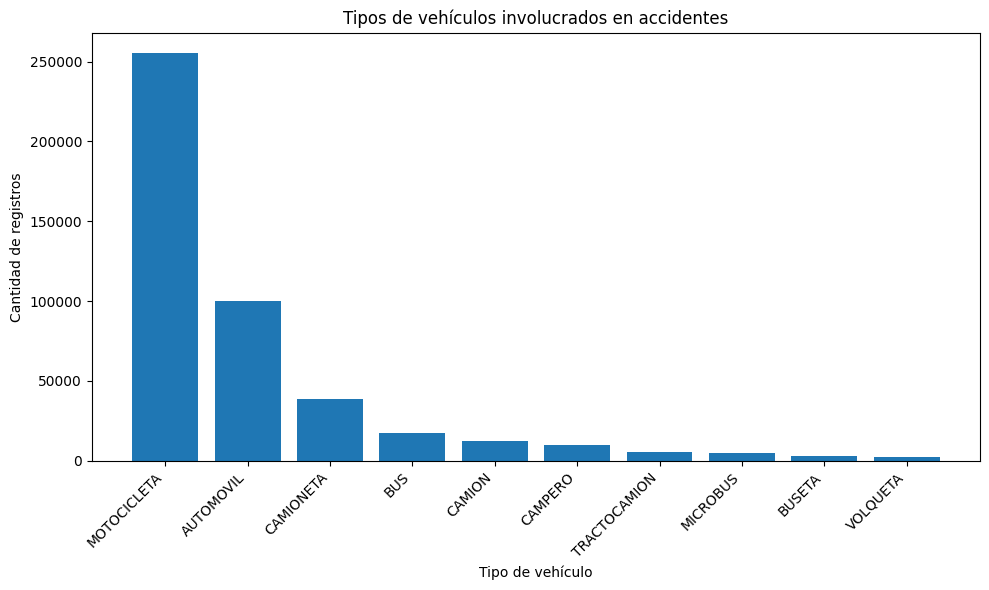

In [13]:
import matplotlib.pyplot as plt

datos_grafica = (
    vehiculos
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(10, 6))
plt.bar(
    datos_grafica["TIPO_VEHICULO"].astype(str),
    datos_grafica["count"]
)

plt.title("Tipos de vehículos involucrados en accidentes")
plt.xlabel("Tipo de vehículo")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
vehiculos.show(20, truncate=False)

+---------------+------+
|TIPO_VEHICULO  |count |
+---------------+------+
|MOTOCICLETA    |255266|
|AUTOMOVIL      |99900 |
|CAMIONETA      |38438 |
|BUS            |17439 |
|CAMION         |12274 |
|CAMPERO        |9691  |
|TRACTOCAMION   |5797  |
|MICROBUS       |4813  |
|BUSETA         |3168  |
|VOLQUETA       |2221  |
|MOTOCARRO      |1048  |
|CICLOMOTOR     |160   |
|CUATRIMOTO     |32    |
|CUADRICICLO    |21    |
|TRACTOR        |16    |
|MAQ. AGRICOLA  |10    |
|MONTACARGAS    |9     |
|RETROEXCAVADORA|5     |
|MINICARGADOR   |4     |
|CARGADOR       |3     |
+---------------+------+
only showing top 20 rows


In [15]:
gravedad.show(truncate=False)

+------------------+------+
|GRAVEDAD_ACCIDENTE|count |
+------------------+------+
|CON HERIDOS       |426436|
|CON MUERTOS       |23899 |
+------------------+------+



In [16]:
departamentos.show(10, truncate=False)

+----------------------+------+
|DEPARTAMENTO_ACCIDENTE|count |
+----------------------+------+
|ANTIOQUIA             |175618|
|BOGOTA D.C.           |62990 |
|VALLE DEL CAUCA       |56503 |
|SANTANDER             |19595 |
|ATLANTICO             |14997 |
|CUNDINAMARCA          |13845 |
|TOLIMA                |12808 |
|RISARALDA             |12568 |
|BOLIVAR               |10410 |
|CALDAS                |9962  |
+----------------------+------+
only showing top 10 rows


In [17]:
vehiculos.toPandas().to_csv(
    "/content/analisis_tipos_vehiculos.csv",
    index=False,
    encoding="utf-8-sig"
)

gravedad.toPandas().to_csv(
    "/content/analisis_gravedad.csv",
    index=False,
    encoding="utf-8-sig"
)

departamentos.toPandas().to_csv(
    "/content/analisis_departamentos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Los tres archivos se guardaron correctamente.")

Los tres archivos se guardaron correctamente.


In [18]:
from google.colab import files

files.download("/content/analisis_tipos_vehiculos.csv")
files.download("/content/analisis_gravedad.csv")
files.download("/content/analisis_departamentos.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
vehiculos.show(20, truncate=False)

+---------------+------+
|TIPO_VEHICULO  |count |
+---------------+------+
|MOTOCICLETA    |255266|
|AUTOMOVIL      |99900 |
|CAMIONETA      |38438 |
|BUS            |17439 |
|CAMION         |12274 |
|CAMPERO        |9691  |
|TRACTOCAMION   |5797  |
|MICROBUS       |4813  |
|BUSETA         |3168  |
|VOLQUETA       |2221  |
|MOTOCARRO      |1048  |
|CICLOMOTOR     |160   |
|CUATRIMOTO     |32    |
|CUADRICICLO    |21    |
|TRACTOR        |16    |
|MAQ. AGRICOLA  |10    |
|MONTACARGAS    |9     |
|RETROEXCAVADORA|5     |
|MINICARGADOR   |4     |
|CARGADOR       |3     |
+---------------+------+
only showing top 20 rows


In [20]:
gravedad.show(truncate=False)

+------------------+------+
|GRAVEDAD_ACCIDENTE|count |
+------------------+------+
|CON HERIDOS       |426436|
|CON MUERTOS       |23899 |
+------------------+------+



In [21]:
departamentos.show(10, truncate=False)

+----------------------+------+
|DEPARTAMENTO_ACCIDENTE|count |
+----------------------+------+
|ANTIOQUIA             |175618|
|BOGOTA D.C.           |62990 |
|VALLE DEL CAUCA       |56503 |
|SANTANDER             |19595 |
|ATLANTICO             |14997 |
|CUNDINAMARCA          |13845 |
|TOLIMA                |12808 |
|RISARALDA             |12568 |
|BOLIVAR               |10410 |
|CALDAS                |9962  |
+----------------------+------+
only showing top 10 rows


In [22]:
from pyspark.sql import functions as F

faltantes = df.select([
    F.count(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        )
    ).alias(c)
    for c in df.columns
])

faltantes.show(truncate=False)

+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO|
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|0             |0              |0            |20           |0              |0                 |0                     |0                  |0                    |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+



In [23]:
total_registros = df.count()

registros_sin_duplicados = df.dropDuplicates().count()

posibles_duplicados = total_registros - registros_sin_duplicados

print("Total de registros:", total_registros)
print("Registros únicos:", registros_sin_duplicados)
print("Posibles duplicados:", posibles_duplicados)

Total de registros: 450335
Registros únicos: 290936
Posibles duplicados: 159399


In [25]:
from pyspark.sql import functions as F

# Revisar los valores originales de la edad
df.select("EDAD_VEHICULO").show(20, truncate=False)

# Limpiar comas y convertir los valores a número
df_edad = df.withColumn(
    "EDAD_NUMERICA",
    F.regexp_replace(
        F.trim(F.col("EDAD_VEHICULO").cast("string")),
        ",",
        ""
    ).cast("double")
)

# Calcular estadísticas ignorando valores no numéricos
df_edad.select(
    F.min("EDAD_NUMERICA").alias("Edad mínima"),
    F.max("EDAD_NUMERICA").alias("Edad máxima"),
    F.round(F.avg("EDAD_NUMERICA"), 2).alias("Edad promedio"),
    F.count("EDAD_NUMERICA").alias("Registros con edad válida"),
    F.count(F.when(F.col("EDAD_NUMERICA").isNull(), 1))
        .alias("Edades faltantes o inválidas")
).show()

+-------------+
|EDAD_VEHICULO|
+-------------+
|7            |
|3            |
|5            |
|5            |
|4            |
|10           |
|8            |
|46           |
|5            |
|4            |
|7            |
|19           |
|6            |
|5            |
|18           |
|22           |
|2            |
|9            |
|2            |
|5            |
+-------------+
only showing top 20 rows
+-----------+-----------+-------------+-------------------------+----------------------------+
|Edad mínima|Edad máxima|Edad promedio|Registros con edad válida|Edades faltantes o inválidas|
+-----------+-----------+-------------+-------------------------+----------------------------+
|        0.0|     2020.0|        10.88|                   450315|                          20|
+-----------+-----------+-------------+-------------------------+----------------------------+



In [26]:
df_edad.filter(
    F.col("EDAD_NUMERICA") > 100
).select(
    "MODELO_VEHICULO",
    "EDAD_VEHICULO",
    "EDAD_NUMERICA",
    "FECHA_ACCIDENTE",
    "TIPO_VEHICULO"
).show(30, truncate=False)

+---------------+-------------+-------------+---------------+-------------+
|MODELO_VEHICULO|EDAD_VEHICULO|EDAD_NUMERICA|FECHA_ACCIDENTE|TIPO_VEHICULO|
+---------------+-------------+-------------+---------------+-------------+
|2008           |118          |118.0        |07/2026        |CAMION       |
|2008           |127          |127.0        |04/2026        |MOTOCICLETA  |
|1995           |127          |127.0        |04/2026        |AUTOMOVIL    |
|1995           |118          |118.0        |04/2026        |AUTOMOVIL    |
|2007           |2,020        |2020.0       |02/2026        |TRACTOCAMION |
|2008           |127          |127.0        |02/2026        |MOTOCICLETA  |
|2007           |127          |127.0        |02/2026        |MOTOCICLETA  |
|1992           |127          |127.0        |01/2026        |AUTOMOVIL    |
|1979           |127          |127.0        |10/2025        |MOTOCICLETA  |
|1993           |127          |127.0        |10/2025        |CAMIONETA    |
|2008       

In [27]:
df_edad.filter(
    (F.col("EDAD_NUMERICA") >= 0) &
    (F.col("EDAD_NUMERICA") <= 100)
).agg(
    F.count("EDAD_NUMERICA").alias("Registros considerados"),
    F.round(F.avg("EDAD_NUMERICA"), 2).alias("Edad promedio provisional")
).show()

+----------------------+-------------------------+
|Registros considerados|Edad promedio provisional|
+----------------------+-------------------------+
|                450250|                    10.85|
+----------------------+-------------------------+



In [28]:
df_edad.filter(
    (F.col("EDAD_NUMERICA") >= 0) &
    (F.col("EDAD_NUMERICA") <= 100)
).agg(
    F.count("EDAD_NUMERICA").alias("Registros considerados"),
    F.round(F.avg("EDAD_NUMERICA"), 2).alias("Edad promedio provisional")
).show()

+----------------------+-------------------------+
|Registros considerados|Edad promedio provisional|
+----------------------+-------------------------+
|                450250|                    10.85|
+----------------------+-------------------------+



In [29]:
df_edad.filter(
    F.col("EDAD_NUMERICA") > 100
).groupBy(
    "EDAD_VEHICULO", "EDAD_NUMERICA"
).count().orderBy(
    F.desc("count")
).show(20, truncate=False)

+-------------+-------------+-----+
|EDAD_VEHICULO|EDAD_NUMERICA|count|
+-------------+-------------+-----+
|127          |127.0        |59   |
|107          |107.0        |2    |
|118          |118.0        |2    |
|2,020        |2020.0       |1    |
|1,826        |1826.0       |1    |
+-------------+-------------+-----+



In [30]:
from pyspark.sql import functions as F

df_limpio = df_edad.filter(
    (F.col("EDAD_NUMERICA") >= 0) &
    (F.col("EDAD_NUMERICA") <= 100)
)

print("Registros originales:", df.count())
print("Registros con edad válida:", df_limpio.count())

df_limpio.select(
    F.round(F.avg("EDAD_NUMERICA"), 2).alias("Edad_promedio"),
    F.min("EDAD_NUMERICA").alias("Edad_minima"),
    F.max("EDAD_NUMERICA").alias("Edad_maxima")
).show()

Registros originales: 450335
Registros con edad válida: 450250
+-------------+-----------+-----------+
|Edad_promedio|Edad_minima|Edad_maxima|
+-------------+-----------+-----------+
|        10.85|        0.0|       87.0|
+-------------+-----------+-----------+



In [31]:
from pyspark.sql import functions as F

analisis_gravedad = df.groupBy(
    "GRAVEDAD_ACCIDENTE"
).agg(
    F.count("*").alias("CANTIDAD")
).orderBy(
    F.desc("CANTIDAD")
)

total = df.count()

analisis_gravedad = analisis_gravedad.withColumn(
    "PORCENTAJE",
    F.round(F.col("CANTIDAD") * 100 / total, 2)
)

analisis_gravedad.show(truncate=False)

+------------------+--------+----------+
|GRAVEDAD_ACCIDENTE|CANTIDAD|PORCENTAJE|
+------------------+--------+----------+
|CON HERIDOS       |426436  |94.69     |
|CON MUERTOS       |23899   |5.31      |
+------------------+--------+----------+



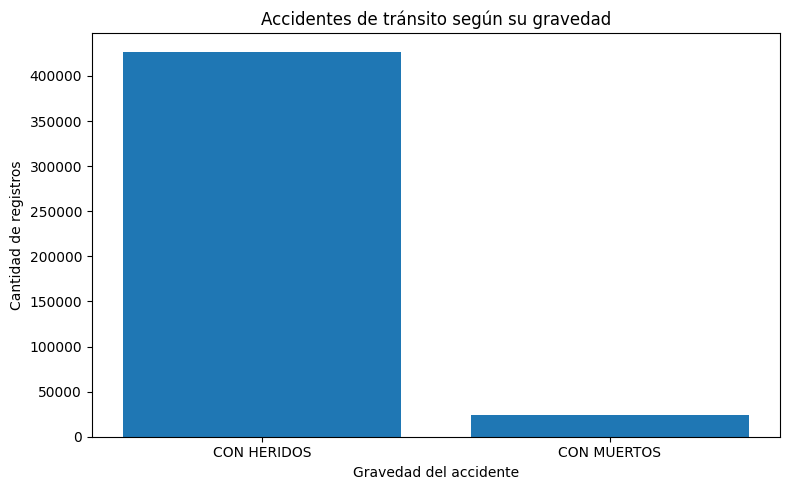

In [32]:
import matplotlib.pyplot as plt

datos_gravedad = analisis_gravedad.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(
    datos_gravedad["GRAVEDAD_ACCIDENTE"],
    datos_gravedad["CANTIDAD"]
)

plt.title("Accidentes de tránsito según su gravedad")
plt.xlabel("Gravedad del accidente")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
from pyspark.sql import functions as F

analisis_departamentos = df.groupBy(
    "DEPARTAMENTO_ACCIDENTE"
).agg(
    F.count("*").alias("CANTIDAD")
).orderBy(
    F.desc("CANTIDAD")
)

analisis_departamentos.show(10, truncate=False)

+----------------------+--------+
|DEPARTAMENTO_ACCIDENTE|CANTIDAD|
+----------------------+--------+
|ANTIOQUIA             |175618  |
|BOGOTA D.C.           |62990   |
|VALLE DEL CAUCA       |56503   |
|SANTANDER             |19595   |
|ATLANTICO             |14997   |
|CUNDINAMARCA          |13845   |
|TOLIMA                |12808   |
|RISARALDA             |12568   |
|BOLIVAR               |10410   |
|CALDAS                |9962    |
+----------------------+--------+
only showing top 10 rows


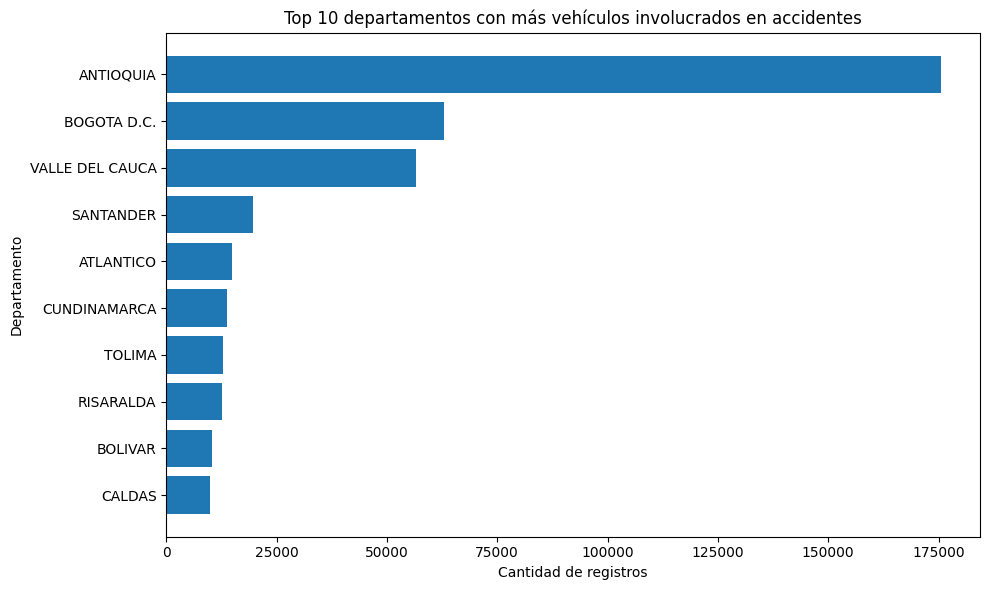

In [34]:
import matplotlib.pyplot as plt

datos_departamentos = analisis_departamentos.limit(10).toPandas()

plt.figure(figsize=(10, 6))
plt.barh(
    datos_departamentos["DEPARTAMENTO_ACCIDENTE"][::-1],
    datos_departamentos["CANTIDAD"][::-1]
)

plt.title("Top 10 departamentos con más vehículos involucrados en accidentes")
plt.xlabel("Cantidad de registros")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

In [35]:
analisis_tipos = df.groupBy(
    "TIPO_VEHICULO"
).agg(
    F.count("*").alias("CANTIDAD")
).orderBy(
    F.desc("CANTIDAD")
)

analisis_tipos.show(10, truncate=False)

+-------------+--------+
|TIPO_VEHICULO|CANTIDAD|
+-------------+--------+
|MOTOCICLETA  |255266  |
|AUTOMOVIL    |99900   |
|CAMIONETA    |38438   |
|BUS          |17439   |
|CAMION       |12274   |
|CAMPERO      |9691    |
|TRACTOCAMION |5797    |
|MICROBUS     |4813    |
|BUSETA       |3168    |
|VOLQUETA     |2221    |
+-------------+--------+
only showing top 10 rows


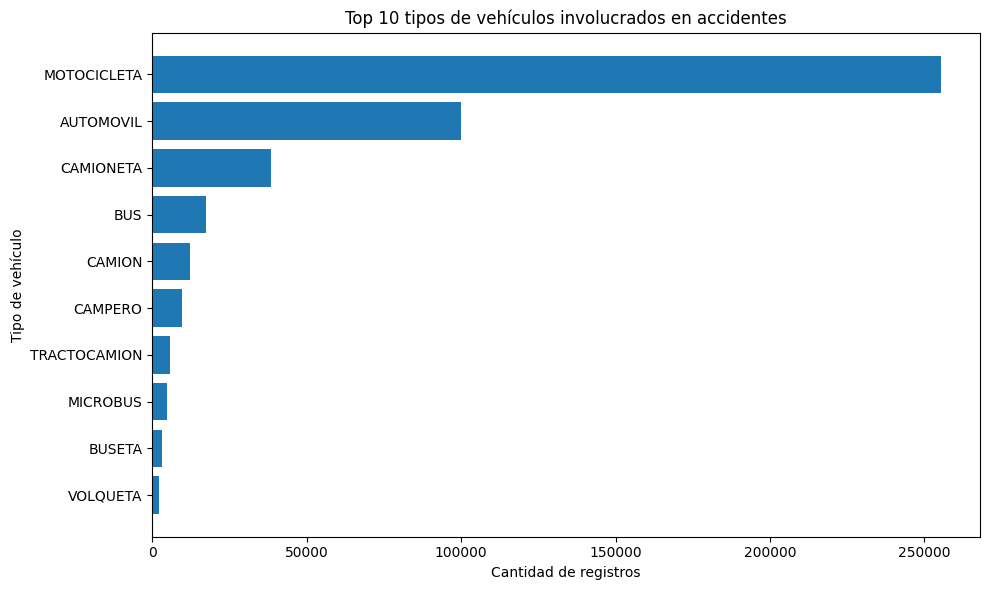

In [36]:
import matplotlib.pyplot as plt

datos_tipos = analisis_tipos.limit(10).toPandas()

plt.figure(figsize=(10, 6))
plt.barh(
    datos_tipos["TIPO_VEHICULO"][::-1],
    datos_tipos["CANTIDAD"][::-1]
)

plt.title("Top 10 tipos de vehículos involucrados en accidentes")
plt.xlabel("Cantidad de registros")
plt.ylabel("Tipo de vehículo")
plt.tight_layout()
plt.show()

In [37]:
df.printSchema()

root
 |-- MARCA_VEHICULO: string (nullable = true)
 |-- MODELO_VEHICULO: integer (nullable = true)
 |-- TIPO_VEHICULO: string (nullable = true)
 |-- EDAD_VEHICULO: string (nullable = true)
 |-- FECHA_ACCIDENTE: string (nullable = true)
 |-- GRAVEDAD_ACCIDENTE: string (nullable = true)
 |-- DEPARTAMENTO_ACCIDENTE: string (nullable = true)
 |-- MUNICIPIO_ACCIDENTE: string (nullable = true)
 |-- AUTORIDAD_DE_TRANSITO: string (nullable = true)



In [38]:
df.show(5, truncate=False)

+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO             |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+----------------------------------+
|VOLKSWAGEN    |2018           |CAMION       |7            |09/2026        |CON HERIDOS       |ANTIOQUIA             |MEDELLIN           |DIRECCION DE TRANSITO Y TRANSPORTE|
|AKT           |2024           |MOTOCICLETA  |3            |09/2026        |CON HERIDOS       |ANTIOQUIA             |MEDELLIN           |DIRECCION DE TRANSITO Y TRANSPORTE|
|YAMAHA        |2022           |MOTOCICLETA  |5            |09/2026        |CON HERIDOS       |ANTIOQUIA             |GIRARDOTA   

In [39]:
df.printSchema()

root
 |-- MARCA_VEHICULO: string (nullable = true)
 |-- MODELO_VEHICULO: integer (nullable = true)
 |-- TIPO_VEHICULO: string (nullable = true)
 |-- EDAD_VEHICULO: string (nullable = true)
 |-- FECHA_ACCIDENTE: string (nullable = true)
 |-- GRAVEDAD_ACCIDENTE: string (nullable = true)
 |-- DEPARTAMENTO_ACCIDENTE: string (nullable = true)
 |-- MUNICIPIO_ACCIDENTE: string (nullable = true)
 |-- AUTORIDAD_DE_TRANSITO: string (nullable = true)



In [40]:
from pyspark.sql import functions as F

df.select([
    F.count(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        )
    ).alias(c)
    for c in df.columns
]).show(truncate=False)

+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|MARCA_VEHICULO|MODELO_VEHICULO|TIPO_VEHICULO|EDAD_VEHICULO|FECHA_ACCIDENTE|GRAVEDAD_ACCIDENTE|DEPARTAMENTO_ACCIDENTE|MUNICIPIO_ACCIDENTE|AUTORIDAD_DE_TRANSITO|
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+
|0             |0              |0            |20           |0              |0                 |0                     |0                  |0                    |
+--------------+---------------+-------------+-------------+---------------+------------------+----------------------+-------------------+---------------------+



In [41]:
print("RESUMEN DEL CONJUNTO DE DATOS")
print("-----------------------------")
print("Número de registros:", df.count())
print("Número de columnas:", len(df.columns))
print("Columnas disponibles:")

for columna in df.columns:
    print("-", columna)

RESUMEN DEL CONJUNTO DE DATOS
-----------------------------
Número de registros: 450335
Número de columnas: 9
Columnas disponibles:
- MARCA_VEHICULO
- MODELO_VEHICULO
- TIPO_VEHICULO
- EDAD_VEHICULO
- FECHA_ACCIDENTE
- GRAVEDAD_ACCIDENTE
- DEPARTAMENTO_ACCIDENTE
- MUNICIPIO_ACCIDENTE
- AUTORIDAD_DE_TRANSITO


In [42]:
analisis_tipos.toPandas().to_csv(
    "/content/analisis_tipos_vehiculos.csv",
    index=False,
    encoding="utf-8-sig"
)

analisis_gravedad.toPandas().to_csv(
    "/content/analisis_gravedad.csv",
    index=False,
    encoding="utf-8-sig"
)

analisis_departamentos.toPandas().to_csv(
    "/content/analisis_departamentos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Los tres archivos CSV se guardaron correctamente.")

Los tres archivos CSV se guardaron correctamente.


In [43]:
from google.colab import files

files.download("/content/analisis_tipos_vehiculos.csv")
files.download("/content/analisis_gravedad.csv")
files.download("/content/analisis_departamentos.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>